<div style="box-sizing:border-box;max-width:100%;margin:0 0 8px;padding:4px 0;color:inherit;line-height:1.35;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:52px!important;max-width:52px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;"><div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:8px 12px;"><span style="min-width:0;color:inherit;font-size:12px;font-weight:700;letter-spacing:0.055em;text-transform:uppercase;"><a href="https://thetahat.ru/courses/ysda-group" style="color:inherit;text-decoration:none;">Школа анализа данных</a>&nbsp;·&nbsp;Машинное обучение</span></div></div>

<h2><span style="display:block;box-sizing:border-box;max-width:100%;padding:16px 22px 17px;border-radius:14px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 50%,#B316B8 100%);color:#FFFFFF;line-height:1.15;font-weight:500;">Домашнее задание 5. Доверительные интервалы в линейных моделях.</span></h2>

<div style="box-sizing:border-box;max-width:100%;margin:18px 0 26px;padding:18px 20px;border:1px solid rgba(127, 127, 127, 0.28);border-left:4px solid #F13A3F;border-radius:12px;background:rgba(127, 127, 127, 0.07);color:inherit;">
  <div style="color:inherit;font-size:12px;font-weight:800;letter-spacing:0.08em;text-transform:uppercase;">Общие правила</div>
  <ul style="margin:10px 0 0;padding-left:22px;line-height:1.55;">
    <li>Выполненную работу <strong>в формате <code>ipynb</code></strong> нужно отправить в кабинете студента <a href="https://thetahat.ru/"><strong>на сайте ThetaHat</strong></a>. Инструкция по регистрации на сайте, записи на курс и сдаче домашек есть на странице курса в ЛМС. <strong>Работы, присланные иным способом, не принимаются.</strong> Дедлайны указаны в личном кабинете, они являются строгими.</li>
    <li>Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><strong>руководство по оформлению ДЗ</strong></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.</li>
    <li>Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><strong>правила использования ИИ-инструментов</strong></a> при решении домашнего задания.</li>
    <li>Выполнять задание необходимо полностью самостоятельно. <strong>При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф согласно правилам на странице курса.</strong></li>
    <li>Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/thetagrader"><img src="https://thetahat.ru/images/ai_eval_small.png" style="display:inline;vertical-align:middle;" alt="ThetaGrader"></a> <a href="https://thetahat.ru/thetagrader"><strong>ThetaGrader</strong></a>. Результаты проверки будут отправлены вам в течение 1-2 суток после дедлайна. После вы можете исправить ошибки или аргументировать свое мнение и отправить на проверку проверяющему. Подробнее на странице курса в ЛМС.</li>
    <li>Никакой код из данного задания при проверке запускаться не будет. <em>Если код не выполнен, недописан и т.д., то он не оценивается.</em></li>
  </ul>
  </br>
    
  <div style="color:inherit;font-size:12px;font-weight:800;letter-spacing:0.08em;text-transform:uppercase;">Правила заполнения ноутбука</div>
  <ul style="margin:8px 0 0;padding-left:22px;line-height:1.55;">
    <li>Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.</li>
    <li>Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены <code>&lt;...&gt;</code>.</li>
    <li>Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках. Выполнение задания (ход решения, выводы и пр.) должно быть осуществлено на русском языке.</li>
    <li>В markdown-ячейках, содержащих описание задачи, находятся специальные отметки, которые <strong style="color:red;">запрещается модифицировать</strong>.</li>
    <li>Решение теоретических задач оформляйте в markdown-ячейках в формате $\LaTeX$. При решении можно использовать ИИ-инструменты для оформления написанного самостоятельно решения, например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.</li>
    <li>При нарушении данных правил работа может получить 0 баллов.</li>
  </ul>
</div>

## 🔵 <font color="blue">Часть L</font>

Дедлайн по части M во вторник 20.10 в 16:00. Дедлайн по этой части **в субботу 24.10 в 23:59**. Подробнее в описании курса в ЛМС.


**Баллы эту часть задания:**

* Задача 3 &mdash; 150 баллов.

In [75]:
import warnings

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as sps
import seaborn as sns
from sklearn import metrics
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_blobs
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    classification_report,
    log_loss,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, OneHotEncoder, PolynomialFeatures, StandardScaler
from tqdm import tqdm


sns.set(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)

# Сюда можно дописать необходимые импорты

In [76]:
# Bot check

# HW_ID: ysda_ml1_task_l5
# Система проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так система проверит, что ты ничего не перепутал, и отправляешь финальную версию,
# а не промежуточную. После отправки работы со статусом final до дедлайна все
# еще можно вносить исправления и отправлять повторно.

# Никакие значения в этой ячейке не влияют на факт сдачи работы.

---

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.


**Задача 3**
1. ссылка
    - для чего использована


---
### <span style="display:inline-block;padding:6px 13px;border-radius:999px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 55%,#B316B8 100%);color:#FFFFFF;font-size:16px;font-weight:700;line-height:1.2;">Задача 3</span>

Рассмотрим датасет [NYC Taxi Trip Duration](https://www.kaggle.com/competitions/nyc-taxi-trip-duration/data). Этот датасет содержит данные о поездках жёлтых такси в Нью-Йорке за 2016 год. Его собрала компания NYC Taxi and Limousine Commission (TLC) — официальный регулятор такси в Нью-Йорке. Информация включает время и место начала и окончания поездки, её длительность, расстояние, количество пассажиров, тип поставщика и другие характеристики.

Изначально данные использовались в конкурсе на Kaggle, где участникам нужно было создать модель для прогнозирования времени поездки. Набор данных полезен для анализа городского трафика, регрессионных задач, прогнозирования спроса на такси, оценки загруженности районов, моделирования пробок и анализа транспортной инфраструктуры.

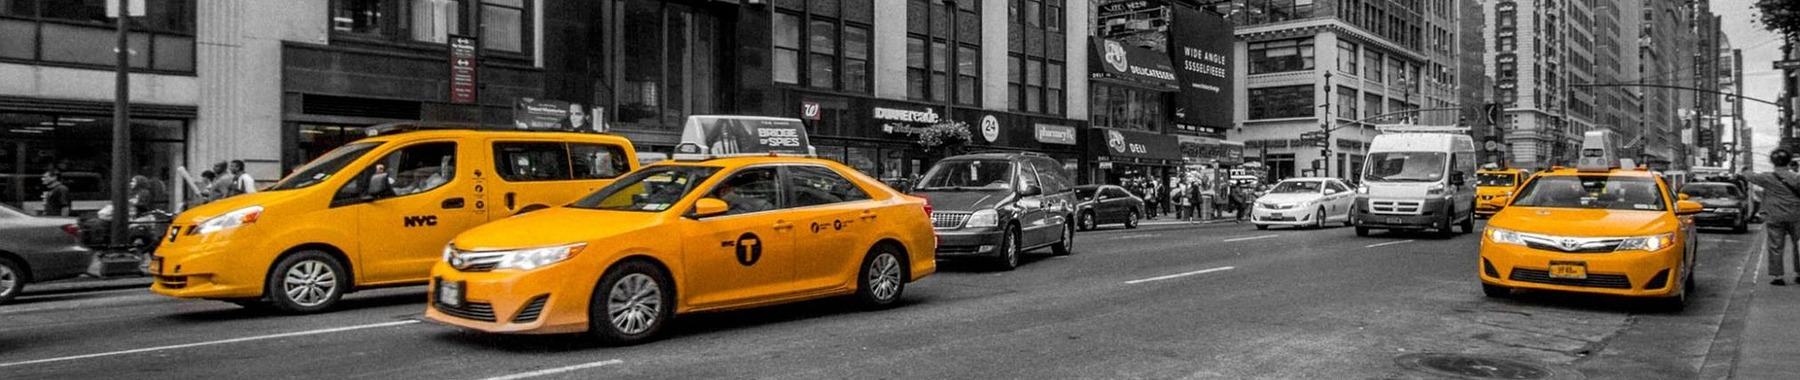

**Описание признаков**

* `id` — уникальный идентификатор поездки;  
* `vendor_id` — идентификатор поставщика (`1` или `2`, разные операторы такси);  
* `pickup_datetime` — дата и время начала поездки;  
* `dropoff_datetime` — дата и время завершения поездки;  
* `passenger_count` — количество пассажиров в машине;  
* `pickup_longitude`, `pickup_latitude` — координаты точки посадки пассажира;  
* `dropoff_longitude`, `dropoff_latitude` — координаты точки высадки пассажира;  
* `store_and_fwd_flag` — индикатор, сохранялись ли данные поездки локально перед передачей (`Y`/`N`);  
* `trip_duration` — длительность поездки в секундах (**таргет**).

**Задача**

Построить модель регрессии для прогнозирования длительности поездки по признакам, доступным в начале поездки — например, по времени, координатам и числу пассажиров.

Также практический интерес представляет построение предсказательных интервалов, позволяющих оценить диапазон возможной продолжительности поездки для конкретного маршрута. Например, *"Поездка от Центрального парка до аэропорта Ла-Гуардия в 8 утра обычно длится от 23 до 27 минут."*


---

Скачаем данные и посмотрим на них

In [77]:
df = pd.read_csv(f"../data/models_stat_properties/nyc-taxi-data.csv")
df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [78]:
df.shape

(1458644, 11)

Данных довольно много. Для отладки кода рекомендуем работать с небольшой подвыборкой

In [4]:
# Убери этот код для финального прогона
df = df.sample(n=20_000, random_state=42).reset_index(drop=True)

**1.** **Генерация признаков исходя из постановки задачи**

Некоторые преобразования признаков можно совершить только на основе знаний предметной сферы вне зависимости от  конкретных данных. Для удобства в рамках исследования эти преобразования можно сделать сразу на всех данных без деления на трейн и тест.

Переведем секунды в минуты, с ними нам привычнее иметь дело, когда речь идет о поездках на такси по городу

In [79]:
df["trip_duration_min"] = df["trip_duration"] / 60.0

Также полезно будет учитывать расстояние между точками посадки и высадки пассажиров. Можно использовать евклидово расстояние между координатами (`pickup_longitude`, `pickup_latitude`) и (`dropoff_longitude`, `dropoff_latitude`). Однако, это расстояние не учитывает кривизну Земли. В рамках одного города это может быть не существенно, тем не менее, для наглядности рассмотрим, как вычислить реальное расстояние в километрах.

> Расстояние между двумя точками на поверхности Земли, заданными широтой и долготой можно вычислить по формуле Haversine дугового расстояния
> 
> $$
d = 2R \arcsin\left(\sqrt{\sin^2\left(\frac{\Delta\varphi}{2}\right) + \cos \varphi_1 \cos \varphi_2 \sin^2\left(\frac{\Delta\lambda}{2}\right)}\right)
$$
> 
> где:  
> - $\varphi_1, \varphi_2$ — широта точек (в радианах),  
> - $\lambda_1, \lambda_2$ — долгота точек (в радианах),  
> - $R = 6371$ км — радиус Земли,  
> - $\Delta\varphi = \varphi_2 - \varphi_1$,
> - $\Delta\lambda = \lambda_2 - \lambda_1$.



In [80]:
from typing import Union
Coordinate = Union[float, np.ndarray, pd.Series]

def haversine(lat1: Coordinate, lon1: Coordinate, lat2: Coordinate, lon2: Coordinate) -> np.ndarray:
    """
    Вычисляет расстояние между двумя точками на Земле по формуле гаверсина.

    Параметры
    ----------
    lat1: Широта первой точки в градусах.
    lon1: Долгота первой точки в градусах.
    lat2: Широта второй точки в градусах.
    lon2: Долгота второй точки в градусах.

    Возвращает
    -------
    np.ndarray
        Расстояние между точками в километрах.
    """
    R = 6371.0  # Средний радиус Земли в километрах

    # Преобразование градусов в радианы для вычислений
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)

    # Основная формула Гаверсина
    a = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2) ** 2
    # Использование arctan2 для большей точности
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return R * c

In [81]:
df["distance_km"] = haversine(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"],
)

Посчитаем среднюю скорость в километрах в час. *Заметьте, что она определяется на основе таргета, ее нельзя будет использовать как признак.*

In [82]:
df["speed"] = df["distance_km"] / (df["trip_duration_min"] / 60)

Построим признаки на основе даты, вы можете по своему усмотрению использовать их или не использовать

In [83]:
# День недели (0 = понедельник)
df["weekday"] = pd.to_datetime(df["pickup_datetime"]).dt.weekday
# Выходные
df["is_weekend"] = (df["weekday"] >= 5).astype(int)
# Часы
df["hour"] = pd.to_datetime(df["pickup_datetime"]).dt.hour
# Утренний час-пикc
df["is_peak_morning"] = df["hour"].between(7, 11).astype(int)
# Вечерний час-пик
df["is_peak_evening"] = df["hour"].between(16, 20).astype(int)

In [84]:
df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,trip_duration_min,distance_km,speed,weekday,is_weekend,hour,is_peak_morning,is_peak_evening
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455,7.583333,1.498521,11.856428,0,0,17,0,1
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663,11.050000,1.805507,9.803659,6,1,0,0,0
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124,35.400000,6.385098,10.822201,1,0,11,1,0
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429,7.150000,1.485498,12.465721,2,0,19,0,1
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435,7.250000,1.188588,9.836594,5,1,13,0,0


Можем добавить какую-то нелинейность. Например, вы можете взять примеры ниже или же предложить свои

In [85]:
# некоторые признаки можно убрать
df["dist_peak_morning"] = df["distance_km"] * df["is_peak_morning"]
df["dist_peak_evening"] = df["distance_km"] * df["is_peak_evening"]
df["dist_weekend"] = df["distance_km"] * df["is_weekend"]
df["dist2"] = df["distance_km"] ** 2
df["log_dist"] = np.log1p(df["distance_km"])

# придумайте свои признаки исходя из постановки задачи
df["is_daylight"] = df["hour"].between(7, 22).astype(int)
df["dist_daylight"] = df["distance_km"] * df["is_daylight"]

Разделите данные на обучающую и тестовую части

In [86]:
df_train, df_test = train_test_split(
    df,
    test_size=0.25,
    random_state=0,
)

**2.** **Фильтрация данных**

Посмотрим на распределение данных. 
* Постройте гистограммы для длительности поездки и для расстояния.
* Постройте scatterplot для этих двух признаков (указывайте малое значение непрозрачности `alpha` для информативности графика, на полных данных не более 0.01).

Что можно сказать про эти признаки?

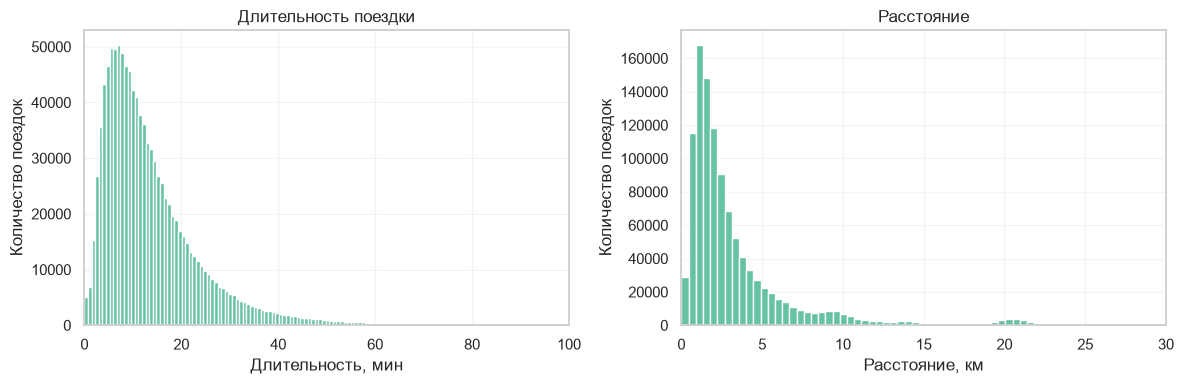

In [144]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_train["trip_duration_min"].dropna(), bins=50000)
axes[0].set(
    title="Длительность поездки",
    xlabel="Длительность, мин",
    ylabel="Количество поездок",
    xlim=(0, 100),
)

axes[1].hist(df_train["distance_km"].dropna(), bins=2000)
axes[1].set(
    title="Расстояние",
    xlabel="Расстояние, км",
    ylabel="Количество поездок",
    xlim=(0, 30),O
)

for ax in axes:
    ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

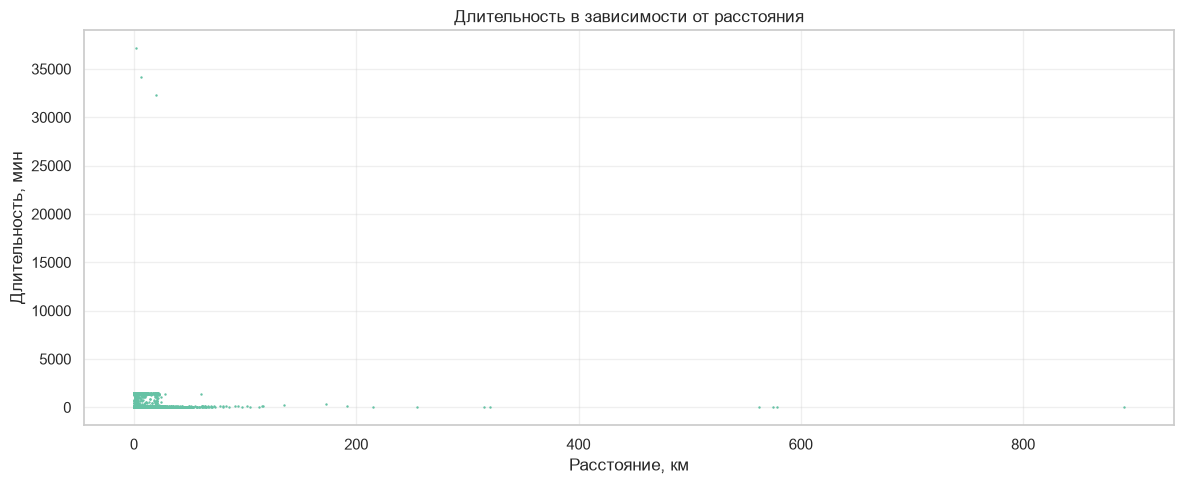

In [88]:
fig, ax_scatter = plt.subplots(figsize=(12, 5))

ax_scatter.scatter(
    df_train["distance_km"],
    df_train["trip_duration_min"],
    alpha=1,
    s=3,
    linewidths=0,
    rasterized=True,
)
ax_scatter.set(
    title="Длительность в зависимости от расстояния",
    xlabel="Расстояние, км",
    ylabel="Длительность, мин",
)
ax_scatter.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

На графиках явно заметны выбросы, удалите их и снова постройте scatterplot. Сколько процентов данных пришлось удалить?

In [89]:
# Удалим данные лежащие под достаточно высокой и крутой прямой.
a = 60/15  # Минут на км.
b = 80  # Не меньше 80 минут.

mask = df_train["trip_duration_min"] <= a * df_train["distance_km"] + b
df_filtered = df_train.loc[mask].copy()

total = len(df_train)
remaining = len(df_filtered)
removed = total - remaining

print(f"Было: {total}")
print(f"Осталось: {remaining}")
print(f"Удалено: {removed}")
if total:
    print(f"Удалено: {removed / total:.2%}")

Было: 1093983
Осталось: 1092273
Удалено: 1710
Удалено: 0.16%


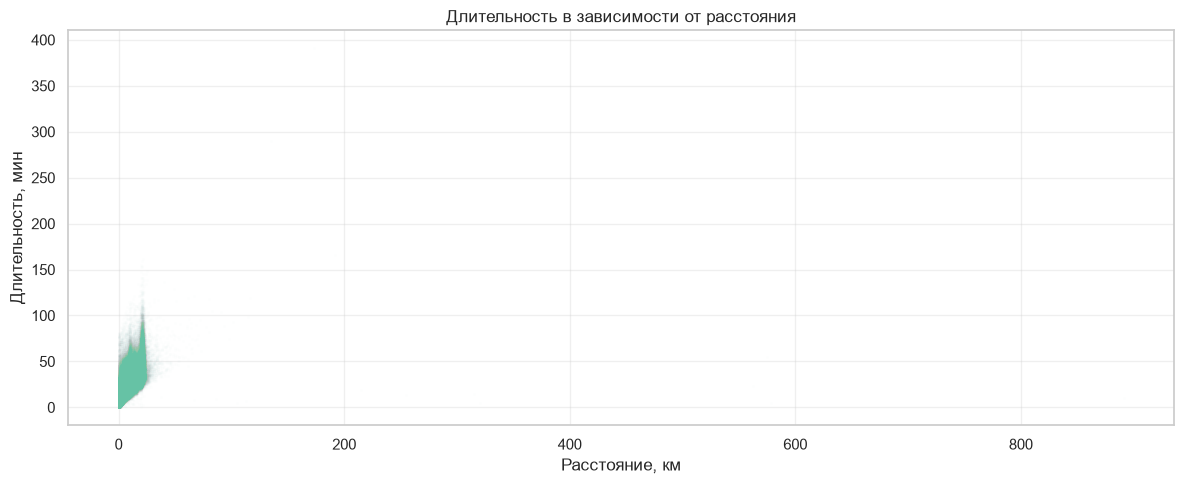

In [140]:
fig, ax_scatter = plt.subplots(figsize=(12, 5))

ax_scatter.scatter(
    df_filtered["distance_km"],
    df_filtered["trip_duration_min"],
    alpha=0.01,
    s=3,
    linewidths=0,
    rasterized=True,
)
ax_scatter.set(
    title="Длительность в зависимости от расстояния",
    xlabel="Расстояние, км",
    ylabel="Длительность, мин",
)
ax_scatter.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

Если вы немного пожалели данные при удалении выбросов выше, на обновленном графике вы увидите еще сгусток выбросов. Возможно, это связано с поездками в определенную точку Нью-Йорка. Такие поездки можно обрабатывать как-то отдельно, сейчас же для простоты сосредоточимся только на обработке основного набора данных.

При необходимости удалите оставшиеся выбросы и снова постройте scatterplot. В результате должны остаться поездки до 15-18 км и до 60-80 минут. Сколько процентов данных пришлось удалить?

In [91]:
# Хм, ну давайте возьмем менее крутую прямую и дополнительно обрежем по расстоянию.
a = 80/20  # Минут на км.
b = 30 

mask = (df_train["trip_duration_min"] <= a * df_train["distance_km"] + b)  & (df["distance_km"] < 18)
df_filtered2 = df_train.loc[mask].copy()

total = len(df_train)
remaining = len(df_filtered2)
removed = total - remaining

print(f"Было: {total}")
print(f"Осталось: {remaining}")
print(f"Удалено: {removed}")
if total:
    print(f"Удалено: {removed / total:.2%}")

Было: 1093983
Осталось: 1063649
Удалено: 30334
Удалено: 2.77%


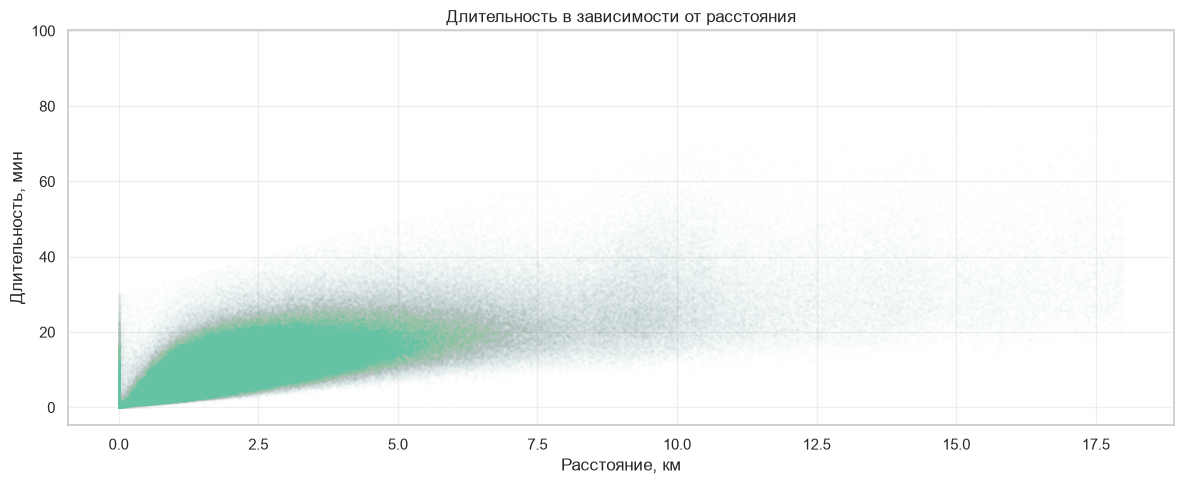

In [137]:
fig, ax_scatter = plt.subplots(figsize=(12, 5))

ax_scatter.scatter(
    df_filtered2["distance_km"],
    df_filtered2["trip_duration_min"],
    alpha=0.01,
    s=3,
    linewidths=0,
    rasterized=True,
)
ax_scatter.set(
    title="Длительность в зависимости от расстояния",
    xlabel="Расстояние, км",
    ylabel="Длительность, мин",
)
ax_scatter.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

Обратите внимание на короткие поездки. На графике можно заметить некоторое количество длительных поездок с нулевым расстоянием. Очевидно, в них что-то пошло не так. Удалите эти точки и снова постройте scatterplot. Все ли теперь хорошо?

In [93]:
# Очевидно... Мало ли что ему очевидно. Нифига это не очевидно, вот что очевидно.

# Удалим по максимально крутой прямой.
a = 20/0.2  # Минут на км.
b = 0.5

mask = (df_filtered2["trip_duration_min"] <= a * df_filtered2["distance_km"] + b)
df_filtered3 = df_filtered2.loc[mask].copy()

total = len(df_train)
remaining = len(df_filtered3)
removed = total - remaining

print(f"Было: {total}")
print(f"Осталось: {remaining}")
print(f"Удалено: {removed}")
if total:
    print(f"Удалено: {removed / total:.2%}")

Было: 1093983
Осталось: 1058642
Удалено: 35341
Удалено: 3.23%


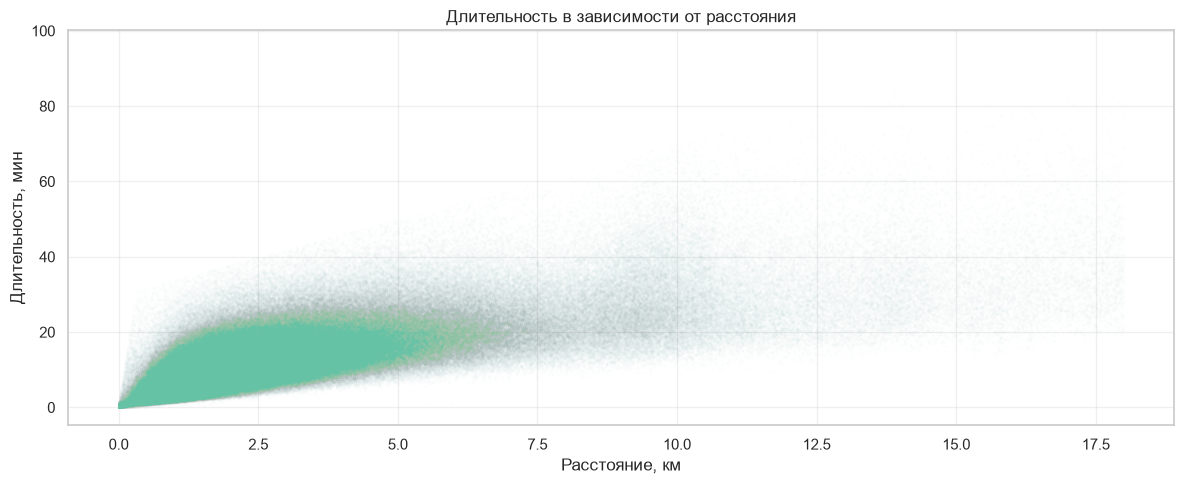

In [139]:
fig, ax_scatter = plt.subplots(figsize=(12, 5))

ax_scatter.scatter(
    df_filtered3["distance_km"],
    df_filtered3["trip_duration_min"],
    alpha=0.01,
    s=3,
    linewidths=0,
    rasterized=True,
)
ax_scatter.set(
    title="Длительность в зависимости от расстояния",
    xlabel="Расстояние, км",
    ylabel="Длительность, мин",
)
ax_scatter.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

Все ли теперь хорошо?
Изначальная фильтрация невозможных данных была оправдана.
А поездки с маленьким расстоянием и большой длительностью вполне имеют право на жизнь.
Просто наша линейная модель просто не сможет их учесть, поэтому их проще вырезать.  
Но в остальном на этом графике данные действительно выглядат достаточно рафинированно.

Постройте гистограмму средней скорости. Есть ли среди водителей Шумахеры? Возможно, их стоит убрать.

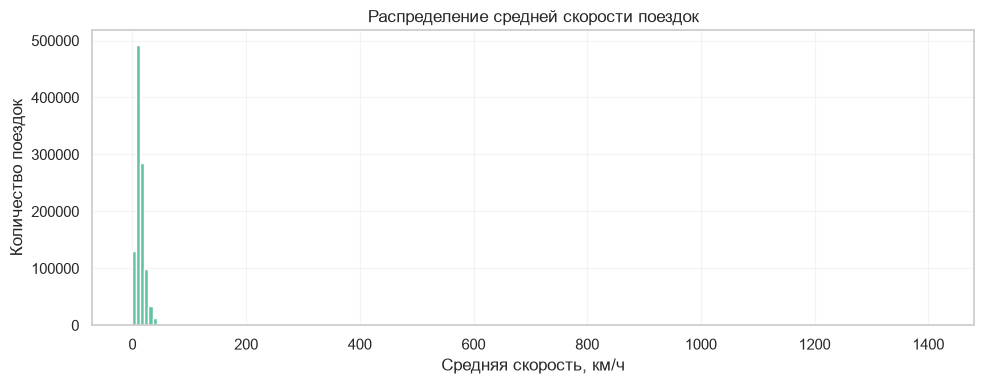

In [95]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(df_filtered3["speed"].dropna(), bins=200)
ax.set(
    title="Распределение средней скорости поездок",
    xlabel="Средняя скорость, км/ч",
    ylabel="Количество поездок",
)
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

In [96]:
df_filtered3["speed"].nlargest(10)

1001028    1410.024743
1107       1265.516683
898154     1244.077521
777670     1095.462175
1200843     913.171260
259403      909.365158
467645      833.253493
334058      815.991099
133641      572.285162
269418      478.884427
Name: speed, dtype: float64

In [97]:
max_speed = 50

mask = df_filtered3["speed"] <= max_speed
removed = (~mask).sum()

df_filtered4 = df_filtered3.loc[mask].copy()

print(f"Удалено: {removed}")
print(f"Осталось: {len(df_filtered)}")

Удалено: 1338
Осталось: 1092273


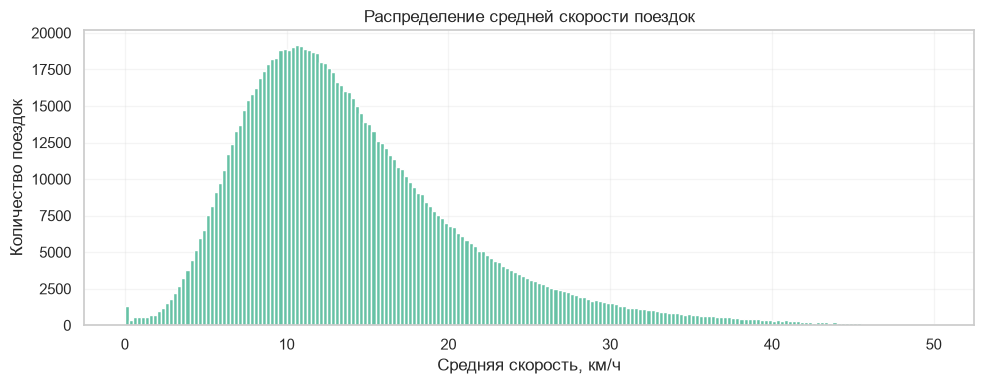

In [98]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(df_filtered4["speed"].dropna(), bins=200)
ax.set(
    title="Распределение средней скорости поездок",
    xlabel="Средняя скорость, км/ч",
    ylabel="Количество поездок",
)
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

**3.** **Обработка признаков на основе данных**


Выполните необходимые преобразования категориальных признаков

In [99]:
def encode_hour(values):
    angle = 2 * np.pi * np.asarray(values, dtype=float) / 24
    return np.column_stack([np.sin(angle), np.cos(angle)])


def hour_feature_names(transformer, input_features):
    return ["hour_sin", "hour_cos"]

def encode_weekday(values):
    angle = 2 * np.pi * np.asarray(values, dtype=float) / 7
    return np.column_stack([np.sin(angle), np.cos(angle)])


def weekday_feature_names(transformer, input_features):
    return ["weekday_sin", "weekday_cos"]


preprocessor = ColumnTransformer(
    transformers=[
        (
            "vendor",
            OneHotEncoder(
                categories=[[1, 2]],
                drop="first",
                sparse_output=False,
            ),
            ["vendor_id"],
        ),
        (
            "hour",
            FunctionTransformer(
                encode_hour,
                feature_names_out=hour_feature_names,
            ),
            ["hour"],
        ),
        (
            "weekday",
            FunctionTransformer(
                encode_weekday,
                feature_names_out=weekday_feature_names,
            ),
            ["weekday"],
        ),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

In [100]:
# Пайплайн будет работать на данных, очищенных от ненужных колонок.
# Сделаем это тут.

feature_cols = [
    "vendor_id",
    "passenger_count",
    "distance_km",
    "weekday",
    "is_weekend",
    "hour",
    "is_peak_morning",
    "is_peak_evening",
    "dist_peak_morning",
    "dist_peak_evening",
    "dist_weekend",
    "dist2",
    "log_dist",
    "is_daylight",
    "dist_daylight",
]
target_col = "trip_duration_min"

X_train = df_filtered4.loc[:, feature_cols].copy()
y_train = df_filtered4[target_col].copy()

X_test = df_test.loc[:, feature_cols].copy()
y_test = df_test[target_col].copy()

На основе проведенного исследования данных или дополнительного анализа некоторых признаков при желании вы можете построить еще какие-либо преобразования признаков. Эту часть можно пропустить если далее получится хорошее качество модели.

In [101]:
...

Ellipsis

**4.** **Анализ линейной регрессии**

Обучите линейную регрессию без регуляризации и посчитайте качество по метрике $R^2$, а также ошибки $RMSE, MAE, MAPE$ на тестовой выборке. При качественном препроцессинге можно получить $MAPE \sim 30\%-35\%$, но в данной задаче будет достаточно $MAPE < 45\%$.

In [102]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])

In [103]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['vendor_id','passenger_count','distance_km',...,'log_dist','is_daylight', 'dist_daylight']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('vendor', ...), ('hour', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passe

In [104]:
y_pred = model.predict(X_test)

print(f"R²:   {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.2f} мин")
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.2f} мин")
print(f"MAPE: {mean_absolute_percentage_error(y_test, y_pred):.2%}")

R²:   -0.6498
RMSE: 141.55 мин
MAE:  6.31 мин
MAPE: 43.16%


*Прежде чем дальше выполнять домашку, убедись, что ты внимательно изучил все материалы с занятия. Там могут быть ответы на многие твои вопросы. Если все же чего-то не нашлось, спроси в чате.*

Визуализируйте зависимость остатков регрессии от нескольких признаков, примеры посмотрите в ноутбуке с занятия. Наблюдается ли гетероскедастичность остатков?

In [105]:
def prepare_residual_plot_data(
    X, y, feature, y_pred, n_points=100, random_state=42
):
    data = pd.DataFrame({
        "feature": np.asarray(X[feature]),
        "actual": np.asarray(y),
        "predicted": np.asarray(y_pred),
    })

    if n_points is not None and len(data) > n_points:
        data = data.sample(n=n_points, random_state=random_state)

    return data

In [108]:
def plot_regression_residuals(data, feature, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))

    residuals = data["actual"] - data["predicted"]
    positive = residuals >= 0

    for mask, color, label in [
        (positive, "#d97757", "Недооценка"),
        (~positive, "#347da2", "Переоценка"),
    ]:
        ax.scatter(
            data.loc[mask, "feature"],
            residuals.loc[mask],
            s=10,
            alpha=0.08,
            color=color,
            edgecolors="none",
            rasterized=True,
            label=label,
        )

    ax.axhline(0, color="#333333", linewidth=1.2, linestyle="--")
    ax.set(
        xlabel=feature,
        ylabel="Остаток, мин",
        title=f"Остатки: {feature}",
    )
    ax.set_axisbelow(True)
    ax.grid(alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, markerscale=3, loc="upper right")

    return ax

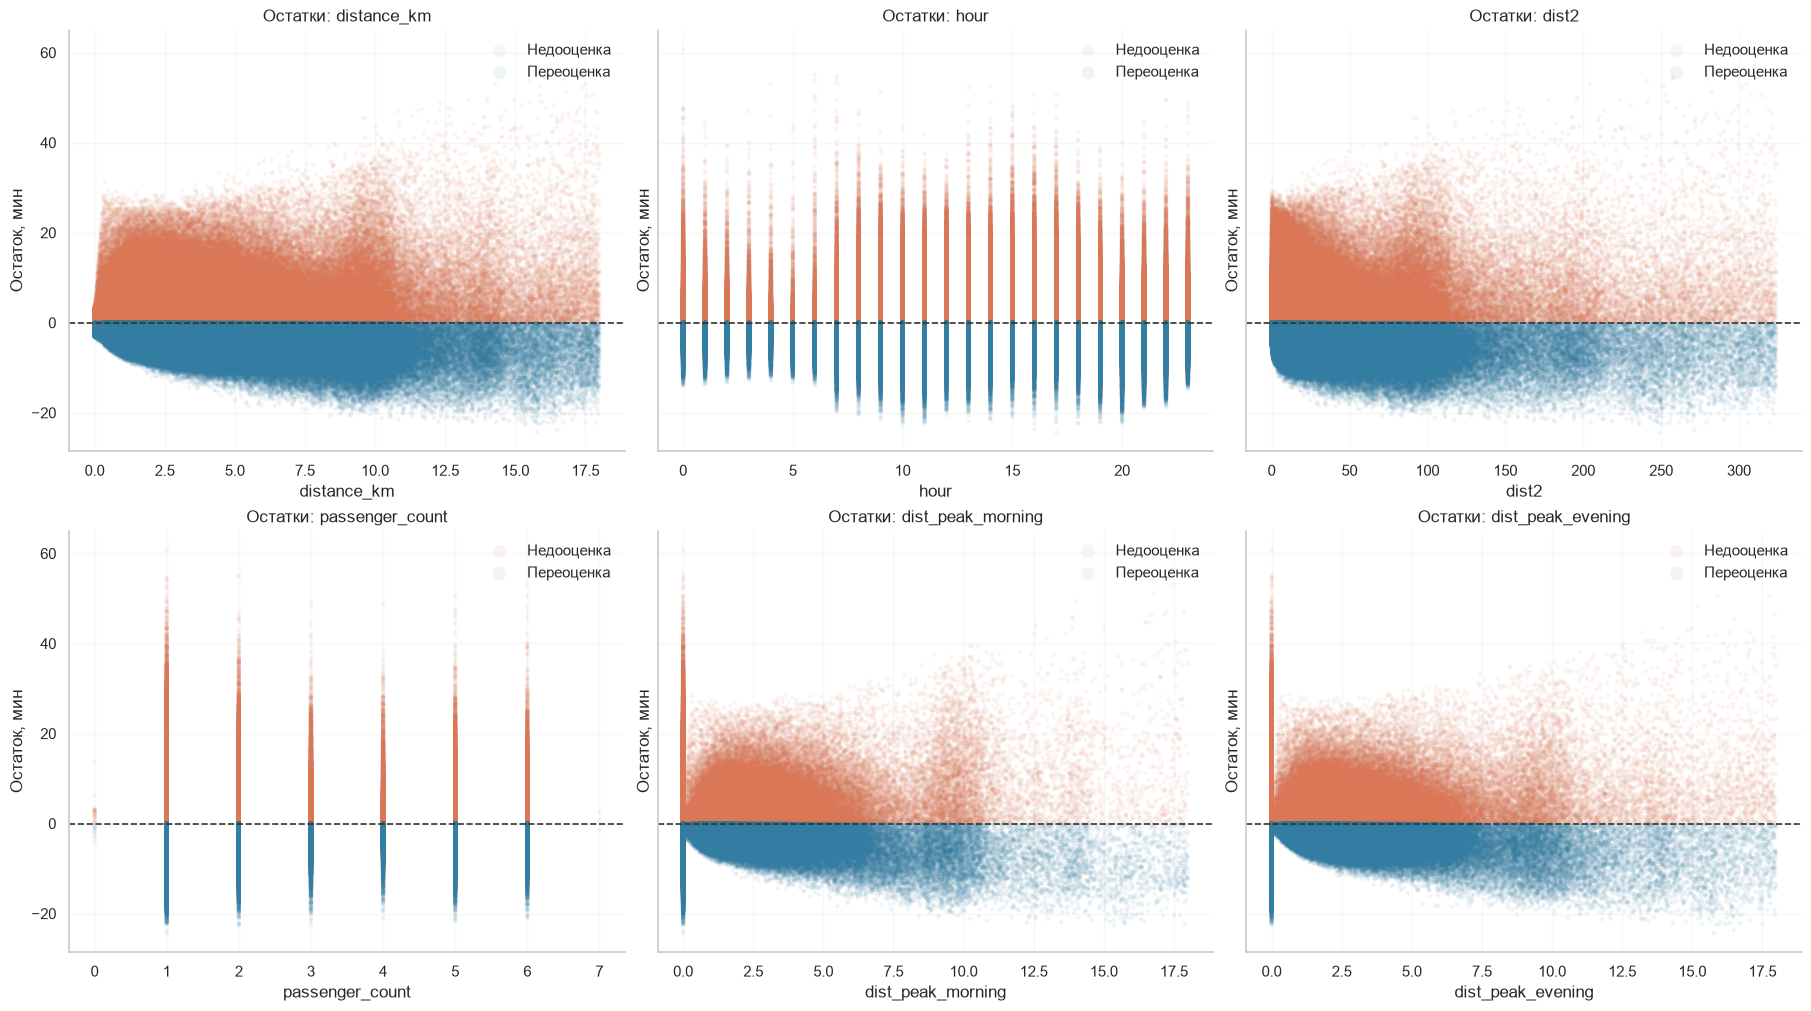

In [109]:
features = [
    "distance_km",
    "hour",
    "dist2",
    "passenger_count",
    "dist_peak_morning",
    "dist_peak_evening",
]

train_pred = model.predict(X_train)

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10),
    sharey=True,
    layout="constrained",
)

for ax, feature in zip(axes.flat, features, strict=True):
    data = prepare_residual_plot_data(
        X_train, y_train, feature, train_pred,
        n_points=None,
    )
    plot_regression_residuals(data, feature, ax=ax)

plt.show()

Гетероскедастичность скорее наблюдается. Разные разбросы в графиках для passenger_count, hour, и distance_km.

Скорее всего вы ответите «да» на предыдущий вопрос. 

Тем не менее, на практике для статистического анализа модели всегда **рекомендуется всегда использовать оценки дисперсии, устойчивые к гетероскедастичности**. Их применение корректно даже в случае гомоскедастичности, соответственно, используя всегда устойчивые оценки мы повышаем надежность модели. 

В данном случае гетероскедастичность вполне ожидаема. Чем больше расстояние поездки, тем больше разброс в длительности из-за множества случайных факторов, которые невозможно предсказать заранее. Поэтому для дальнейших экспериментов обучайте модель, указывая один из типов оценок дисперсии, устойчивых к гетероскедастичности.


Оцените по графику остатков, имеется ли нелинейность по каким-то признакам? Если есть, попробуйте исправить модель. Возможны два случая:
* добавление нелинейного признака,
* монотонное преобразование таргета.

Во втором случае для всех предсказаний и интервалов, которые вы далее будете строить, необходимо сначала построить для преобразованного таргета, а затем выполнить обратное преобразование.

Для новой модели аналогично оцените качество и посмотрите на график остатков.

Я побробовал добавить больше гармоник для hour, но это вообще не помогло. Ни в качестве, ни в изменении характера ошибок.  
Поэтому модель как есть оставил

Посмотрите на summary модели. Какие признаки не оказывают статистически значимого влияния на время поездки? Проверьте, что вы уже используете оценки дисперсии, устойчивые к гетероскедастичности.

In [110]:
import statsmodels.api as sm

X_train_sm = model.named_steps["preprocessor"].transform(X_train)
X_train_sm = sm.add_constant(X_train_sm, has_constant="add")
X_train_sm = X_train_sm.astype(float)

ols_model = sm.OLS(
    np.asarray(y_train, dtype=float),
    X_train_sm,
).fit(cov_type="HC3")

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.659
Model:                            OLS   Adj. R-squared:                  0.659
Method:                 Least Squares   F-statistic:                 8.471e+04
Date:                Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:51:43   Log-Likelihood:            -3.2673e+06
No. Observations:             1057304   AIC:                         6.535e+06
Df Residuals:                 1057286   BIC:                         6.535e+06
Df Model:                          17                                         
Covariance Type:                  HC3                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 1.0955      0.03

In [111]:
coefficient_table = pd.DataFrame({
    "coefficient": ols_model.params,
    "std_error": ols_model.bse,
    "p_value": ols_model.pvalues,
})

print("Значимые признаки")
coefficient_table.loc[
    (coefficient_table["p_value"] >= 0.05)
    & (coefficient_table.index != "const")
]

Значимые признаки


,coefficient,std_error,p_value


In [112]:
print("Невлияющие признаки")
coefficient_table.loc[
    (coefficient_table["p_value"] < 0.05)
    & (coefficient_table.index != "const")
]

Невлияющие признаки


,coefficient,std_error,p_value
vendor_id_2,-0.062140,0.010875,1.102416e-08
hour_sin,-2.559914,0.019496,0.000000e+00
hour_cos,-2.241877,0.010509,0.000000e+00
weekday_sin,0.599133,0.012366,0.000000e+00
weekday_cos,-0.799123,0.007714,0.000000e+00
passenger_count,0.065809,0.004200,2.452601e-55
distance_km,1.318998,0.032425,0.000000e+00
is_weekend,0.079865,0.023512,6.816957e-04
is_peak_morning,1.908661,0.032548,0.000000e+00
is_peak_evening,-1.075358,0.023728,0.000000e+00


Насколько меняется среднее время поездки при увеличении маршрута на 1 километр? Приведите оценку и доверительный интервал. Если ранее выполнили преобразование таргета, не забудьте выполнить обратное преобразование.

In [113]:
X_plus1 = X_test.copy()
X_plus1["distance_km"] = X_test["distance_km"] + 1

X_plus1["dist2"] = X_plus1["distance_km"] ** 2
X_plus1["log_dist"] = np.log1p(X_plus1["distance_km"])

interactions = {
    "dist_peak_morning": "is_peak_morning",
    "dist_peak_evening": "is_peak_evening",
    "dist_weekend": "is_weekend",
    "dist_daylight": "is_daylight",
}

for interaction, flag in interactions.items():
    X_plus1[interaction] = X_plus1["distance_km"] * X_plus1[flag]

In [114]:
y_pred_test = model.predict(X_test)
y_pred_plus1 = model.predict(X_plus1)

delta = sum((y_pred_plus1-y_pred_test))/len(y_pred_plus1)
print(f"Среднее время увеличивается на {delta} минуты")

Среднее время увеличивается на 3.3765028094352054 минуты


In [115]:
# Сделаем то же самое, "достав" матричное умножение из модели.
preprocessor = model.named_steps["preprocessor"]

# Матрицы признаков, над которой модель реально работает.
design_before = preprocessor.transform(X_test)
design_after = preprocessor.transform(X_plus1)
design_before = sm.add_constant(
    design_before, has_constant="add"
).astype(float)
design_after = sm.add_constant(
    design_after, has_constant="add"
).astype(float)

# Разница матриц. Если применить к ней матричное умножение, то это и будет уже посчитанная delta.
columns = ols_model.params.index
contrast = (
    design_after.loc[:, columns] - design_before.loc[:, columns]
)

In [116]:
c = contrast.to_numpy()
coefficients = ols_model.params.to_numpy()
covariance = ols_model.cov_params().to_numpy()

effect = c @ coefficients # delta.

variance = np.einsum("ij,jk,ik->i", c, covariance, c)
standard_error = np.sqrt(np.maximum(variance, 0))

if ols_model.use_t:
    critical = sps.t.ppf(0.975, df=ols_model.df_resid)
else:
    critical = sps.norm.ppf(0.975)

effects = pd.DataFrame({
    "distance_km": X_test["distance_km"],
    "change_min": effect,
    "ci_lower": effect - critical * standard_error,
    "ci_upper": effect + critical * standard_error,
})

In [117]:
effects

,distance_km,change_min,ci_lower,ci_upper
571578,0.444935,5.559466,5.531250,5.587683
1280332,15.988325,0.982267,0.935543,1.028990
177838,8.599361,1.866238,1.846298,1.886179
1433776,2.347030,3.385400,3.368647,3.402152
757662,0.783716,4.779688,4.760405,4.798971
...,...,...,...,...
279330,1.268948,4.375816,4.361358,4.390275
579302,0.597252,5.082397,5.057413,5.107381
494423,0.000000,6.634998,6.584231,6.685766
1098264,0.696782,5.103389,5.081981,5.124796


In [118]:
c_mean = (
    contrast.loc[:, ols_model.params.index]
    .mean(axis=0)
    .to_numpy()
)

effect_mean = c_mean @ ols_model.params.to_numpy()

standard_error = np.sqrt(
    c_mean @ ols_model.cov_params().to_numpy() @ c_mean
)

if ols_model.use_t:
    critical = sps.t.ppf(0.975, df=ols_model.df_resid)
else:
    critical = sps.norm.ppf(0.975)

lower = effect_mean - critical * standard_error
upper = effect_mean + critical * standard_error

print(f"Среднее изменение времени: {effect_mean:.2f} мин")
print(f"95%-й ДИ: [{lower:.2f}; {upper:.2f}] мин")

Среднее изменение времени: 3.38 мин
95%-й ДИ: [3.37; 3.38] мин


**5.** **Доверительные и предсказательные интервалы**

Наша следующая цель &mdash; построить *доверительные* интервалы для *среднего* времени поездки и *предсказательные* интервалы для *фактического* времени поездки.

Сначала построим наглядные графики зависимости интервалов от одного признака &mdash; расстояние поездки. Для этого зафиксируйте значения всех остальных признаков (средним или медианой) и создайте сетку значений для расстояния. Например, от 0 до 15 км с шагом в 50-100 метров.

*Замечание.* Если вы использовали производные признаки от расстояния (например, квадрат расстояния), то такие признаки тоже нужно пересчитать по сетке.

In [119]:
distance_grid = np.linspace(0, 15, 151)  # Шаг 0.1 км.

baseline = X_train.median()

for column in ["vendor_id", "hour", "weekday"]:
    baseline[column] = X_train[column].mode().iloc[0]

X_grid = pd.DataFrame(
    np.tile(baseline.to_numpy(), (len(distance_grid), 1)),
    columns=X_train.columns,
)

X_grid["distance_km"] = distance_grid
X_grid["is_weekend"] = (X_grid["weekday"] >= 5).astype(int)
X_grid["is_peak_morning"] = X_grid["hour"].between(7, 11).astype(int)
X_grid["is_peak_evening"] = X_grid["hour"].between(16, 20).astype(int)
X_grid["is_daylight"] = X_grid["hour"].between(7, 22).astype(int)

X_grid["dist2"] = X_grid["distance_km"] ** 2
X_grid["log_dist"] = np.log1p(X_grid["distance_km"])

interactions = {
    "dist_peak_morning": "is_peak_morning",
    "dist_peak_evening": "is_peak_evening",
    "dist_weekend": "is_weekend",
    "dist_daylight": "is_daylight",
}

for interaction, flag in interactions.items():
    X_grid[interaction] = X_grid["distance_km"] * X_grid[flag]

In [120]:
X_grid[
    ["vendor_id", "passenger_count", "hour", "weekday", "is_weekend"]
].iloc[0]

vendor_id           2.0
passenger_count     1.0
hour               19.0
weekday             4.0
is_weekend          0.0
Name: 0, dtype: float64

In [121]:
grid_design = model.named_steps["preprocessor"].transform(X_grid)

grid_design = sm.add_constant(
    grid_design,
    has_constant="add",
).astype(float)

grid_design = grid_design.loc[:, ols_model.params.index]
grid_predictions = ols_model.get_prediction(grid_design)

In [122]:
intervals = grid_predictions.summary_frame(alpha=0.05)

intervals.head()

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,0.006937,0.031988,-0.055758,0.069633,-10.417864,10.431739
1,0.868079,0.028459,0.812300,0.923858,-9.556683,11.292842
2,1.670453,0.025603,1.620272,1.720634,-8.754281,12.095187
3,2.423364,0.023309,2.377681,2.469048,-8.001349,12.848078
4,3.134046,0.021484,3.091938,3.176153,-7.290653,13.558744


Постройте *доверительные* интервалы для созданной выше сетки и визуализируйте их.

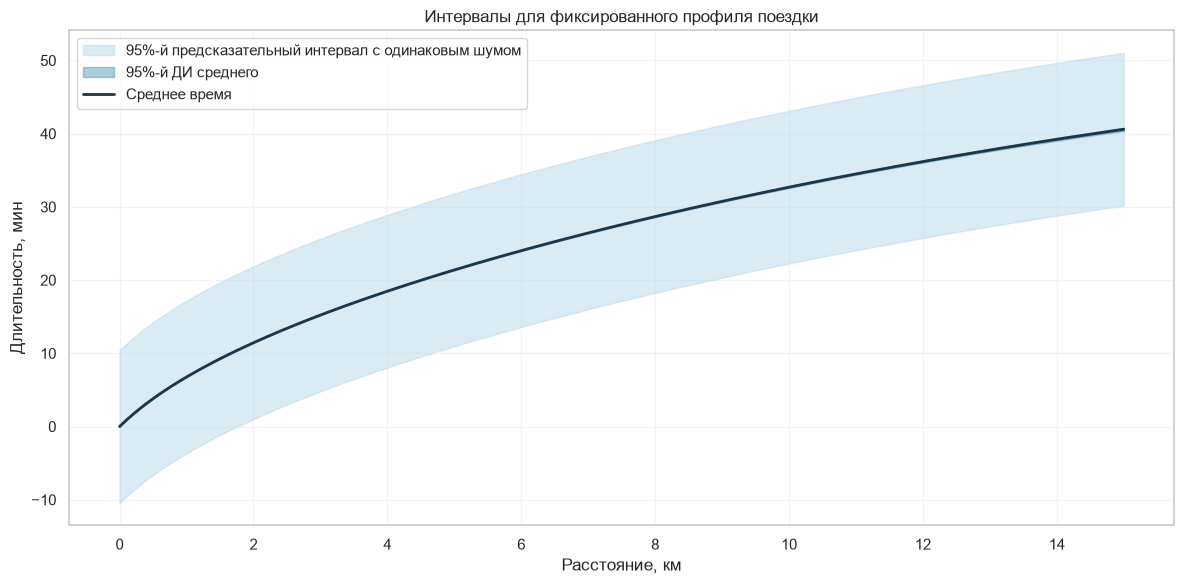

In [123]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.fill_between(
    distance_grid,
    intervals["obs_ci_lower"].to_numpy(),
    intervals["obs_ci_upper"].to_numpy(),
    color="#b8d8eb",
    alpha=0.5,
    label="95%-й предсказательный интервал с одинаковым шумом",
)

ax.fill_between(
    distance_grid,
    intervals["mean_ci_lower"].to_numpy(),
    intervals["mean_ci_upper"].to_numpy(),
    color="#347da2",
    alpha=0.4,
    label="95%-й ДИ среднего",
)

ax.plot(
    distance_grid,
    intervals["mean"].to_numpy(),
    color="#193747",
    linewidth=2,
    label="Среднее время",
)

ax.set(
    xlabel="Расстояние, км",
    ylabel="Длительность, мин",
    title="Интервалы для фиксированного профиля поездки",
)
ax.set_axisbelow(True)
ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()
plt.show()

На занятии мы обсудили, что для построения предсказательных интервалов нужно оценить зависимость дисперсии шума от признаков. Один из способов это сделать — построить еще одну регрессионную модель для предсказания квадрата остатка основной модели.

Создайте такую модель и оцените её качество. Не забудьте, что предсказания квадрата остатка не могут быть отрицательными.

In [124]:
def prepare_ols_design(X, preprocessor, columns):
    transformed = preprocessor.transform(X)
    transformed = sm.add_constant(
        transformed, has_constant="add"
    ).astype(float)
    return transformed.loc[:, columns]


preprocessor = model.named_steps["preprocessor"]

train_design = prepare_ols_design(
    X_train, preprocessor, ols_model.params.index
)
test_design = prepare_ols_design(
    X_test, preprocessor, ols_model.params.index
)

residuals_train = (
    np.asarray(y_train) - np.asarray(ols_model.predict(train_design))
)
residuals_test = (
    np.asarray(y_test) - np.asarray(ols_model.predict(test_design))
)

residuals_squared_train = residuals_train**2
residuals_squared_test = residuals_test**2

In [125]:
from sklearn.base import clone

variance_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", LinearRegression()),
])

variance_model.fit(X_train, residuals_squared_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['vendor_id','passenger_count','distance_km',...,'log_dist','is_daylight', 'dist_daylight']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('vendor', ...), ('hour', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passe

In [126]:
raw_variance_pred = variance_model.predict(X_test)
variance_pred = np.maximum(raw_variance_pred, 0)

print(f"Доля отрицательных до обрезки: {(raw_variance_pred < 0).mean():.2%}")

print(f"R²:   {r2_score(residuals_squared_test, variance_pred):.4f}")
print(
    f"RMSE: {root_mean_squared_error(residuals_squared_test, variance_pred):.2f} мин²"
)
print(
    f"MAE:  {mean_absolute_error(residuals_squared_test, variance_pred):.2f} мин²"
)

Доля отрицательных до обрезки: 0.41%
R²:   -0.0000
RMSE: 7332594.54 мин²
MAE:  20035.45 мин²


Теперь все готово для построения предсказательного интервала. Постройте его и визуализируйте.

In [127]:
intervals = ols_model.get_prediction(grid_design).summary_frame(alpha=0.05)

mean_pred = intervals["mean"].to_numpy()
variance_mean = intervals["mean_se"].to_numpy() ** 2
variance_grid = np.maximum(variance_model.predict(X_grid), 0)

prediction_se = np.sqrt(variance_mean + variance_grid)

critical = sps.t.ppf(0.975, df=ols_model.df_resid)

prediction_lower = mean_pred - critical * prediction_se
prediction_upper = mean_pred + critical * prediction_se

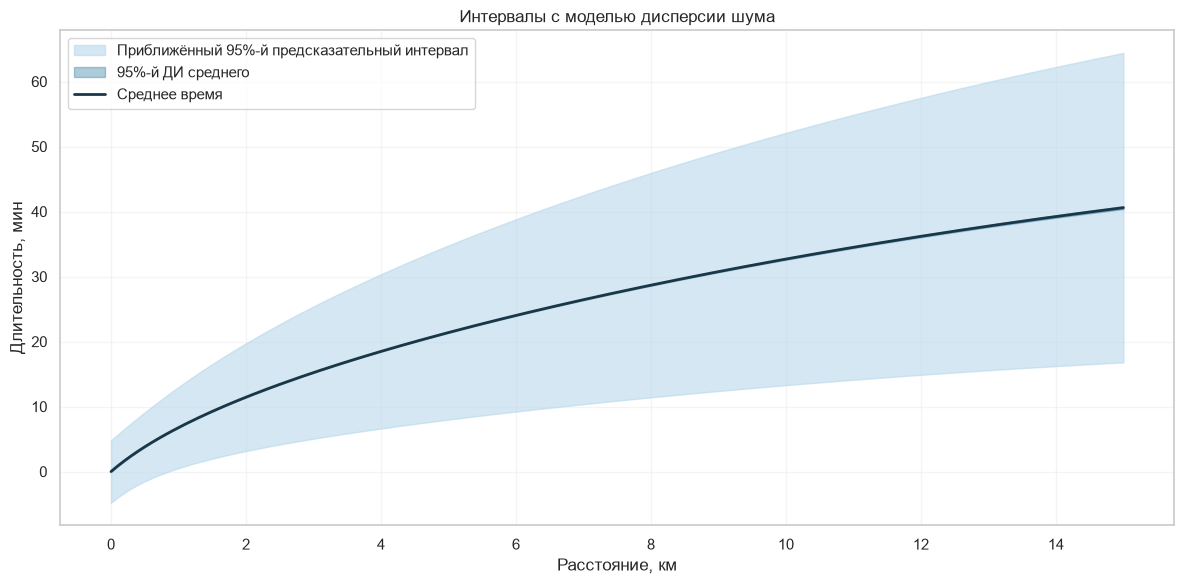

In [128]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.fill_between(
    distance_grid,
    prediction_lower,
    prediction_upper,
    color="#b8d8eb",
    alpha=0.6,
    label="Приближённый 95%-й предсказательный интервал",
)

ax.fill_between(
    distance_grid,
    intervals["mean_ci_lower"].to_numpy(),
    intervals["mean_ci_upper"].to_numpy(),
    color="#347da2",
    alpha=0.4,
    label="95%-й ДИ среднего",
)

ax.plot(
    distance_grid,
    mean_pred,
    color="#193747",
    linewidth=2,
    label="Среднее время",
)

ax.set(
    xlabel="Расстояние, км",
    ylabel="Длительность, мин",
    title="Интервалы с моделью дисперсии шума",
)
ax.set_axisbelow(True)
ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()
plt.show()

Выберите случайных 50-100 поездок из тестовой выборки и постройте для них оба вида интервала — доверительный и предсказательный. Визуализируйте эти интервалы на графике (может помочь `plt.errorbar`).

In [129]:
rng = np.random.default_rng(42)
indices = rng.choice(
    len(X_test),
    size=min(75, len(X_test)),
    replace=False,
)

X_selected = X_test.iloc[indices]
y_selected = np.asarray(y_test)[indices]

selected_design = prepare_ols_design(
    X_selected,
    preprocessor,
    ols_model.params.index,
)

summary = ols_model.get_prediction(selected_design).summary_frame(alpha=0.05)

mean_pred = summary["mean"].to_numpy()
mean_lower = summary["mean_ci_lower"].to_numpy()
mean_upper = summary["mean_ci_upper"].to_numpy()

noise_variance = np.maximum(
    variance_model.predict(X_selected), 0
)
prediction_se = np.sqrt(
    summary["mean_se"].to_numpy() ** 2 + noise_variance
)

critical = sps.t.ppf(0.975, df=ols_model.df_resid)
prediction_margin = critical * prediction_se

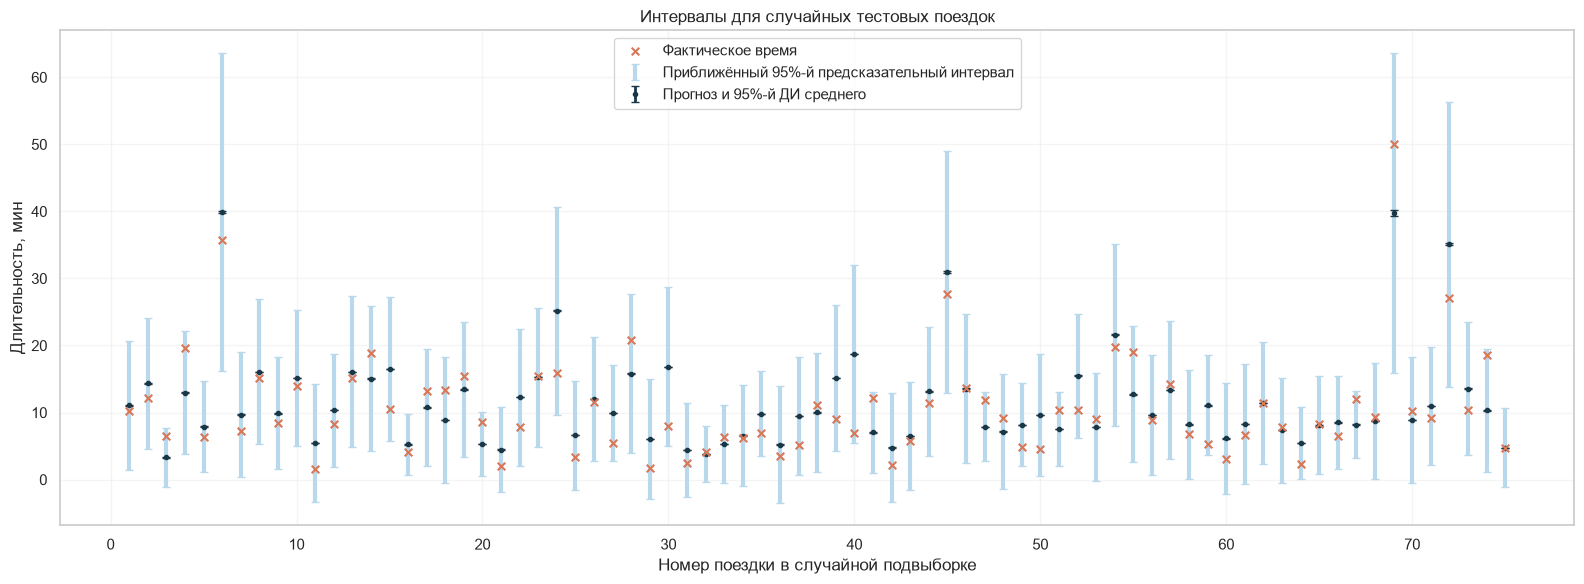

In [130]:
positions = np.arange(1, len(X_selected) + 1)

fig, ax = plt.subplots(figsize=(16, 6))

ax.errorbar(
    positions,
    mean_pred,
    yerr=prediction_margin,
    fmt="none",
    ecolor="#b8d8eb",
    elinewidth=3,
    capsize=3,
    label="Приближённый 95%-й предсказательный интервал",
    zorder=1,
)

ax.errorbar(
    positions,
    mean_pred,
    yerr=np.vstack([
        mean_pred - mean_lower,
        mean_upper - mean_pred,
    ]),
    fmt="o",
    color="#193747",
    markersize=3,
    elinewidth=2,
    capsize=3,
    label="Прогноз и 95%-й ДИ среднего",
    zorder=2,
)

ax.scatter(
    positions,
    y_selected,
    color="#d97757",
    marker="x",
    s=30,
    label="Фактическое время",
    zorder=3,
)

ax.set(
    xlabel="Номер поездки в случайной подвыборке",
    ylabel="Длительность, мин",
    title="Интервалы для случайных тестовых поездок",
)
ax.set_axisbelow(True)
ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()
plt.show()

Какие выводы можно сделать про эти два вида интервалов?

Доверительный интервал сильно меньше, т.к. оценивает только то, насколько близко наша модель к истинной зависимости.  
Предсказательный интервал же еще учитывает шум (или, то, что мы считаем шумом).  
На графике видно что около 95% точек действительно укладываются в предсказательные интервалы.

Наконец, оценим, насколько корректно мы построили предсказательные интервалы. Оцените долю покрытия предсказательным интервалом *фактического* времени поездки по *всем* точкам тестовой выборки.

In [131]:
test_design = prepare_ols_design(
    X_test, preprocessor, ols_model.params.index
)

summary = ols_model.get_prediction(test_design).summary_frame(alpha=0.05)

mean_pred = summary["mean"].to_numpy()
noise_variance = np.maximum(variance_model.predict(X_test), 0)

prediction_se = np.sqrt(
    summary["mean_se"].to_numpy() ** 2 + noise_variance
)

critical = sps.t.ppf(0.975, df=ols_model.df_resid)

lower = mean_pred - critical * prediction_se
upper = mean_pred + critical * prediction_se

actual = np.asarray(y_test)
covered = (lower <= actual) & (actual <= upper)

print(f"Доля покрытия: {covered.mean():.2%}")
print(f"Покрыто поездок: {covered.sum()} из {len(covered)}")
print(f"Средняя ширина интервала: {(upper - lower).mean():.2f} мин")

Доля покрытия: 93.77%
Покрыто поездок: 341927 из 364661
Средняя ширина интервала: 20.15 мин


**6.** **Общие выводы по задаче**

1. Для линейных моделей нужно не забывать предобрабатывать данные. Удалять шумы, выделять нелинейные закономерности, учитывать специфику области.
2. Данные в задаче гетероскедастичны -- разброс ошибок неодинаков. Для выводов нужно использовать робастные оценки ковариации, например, HC3.
3. Некоторые признаки оказались статистически незначимы.
4. Доверительный и предсказательный интервалы это разные вещи и отвечают на разные вопросы. Один про точность оценки среднего времени, второй -- про оценку конкретного предсказания.
5. Качество интервалов можно проверить/посчитать и эмпирически просто посчитав на данных сколько реально точек попало.

<div style="box-sizing:border-box;max-width:100%;margin-top:42px;padding:18px 0 4px;border-top:1px solid rgba(127, 127, 127, 0.28);color:inherit;font-size:0.9em;line-height:1.5;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:34px!important;max-width:34px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;">© 2026 команда <a href="https://thetahat.ru/" style="color:inherit;font-weight:750;text-decoration:underline;text-decoration-color:#F13A3F;text-underline-offset:3px;">ThetaHat</a> для курса ML-1 ШАД</div>